# 변수별 AutoML 모델 선택

## 목적

6개 변수에 공용모델(E3 앙상블: Auto-ARIMA(AIC)+GP-Matern+GP-RBF)을 똑같이 쓰는 대신,
**변수마다 가장 잘 맞는 모델을 CRPS+bootstrap으로 골라본다.**

## 안전장치 (사전 논의로 확정)
- origin을 선택용/검증용으로 쪼개지 않음(표본 22~25개뿐이라 오히려 불안정) — 대신 **bootstrap 마진(60%+ 또는 E3 대비 20%p+)**으로 방어
- 평균(CRPS)뿐 아니라 **최악의 단일 origin 오차**도 같이 봐서 Lasso/ElasticNet 같은 함정 방지
- 여러 변수가 동시에 교체되면 **다중비교 주의** 표시
- 후보 16개(4-2 캐시 11개 + 3-2 캐시 naive/GBM 2개 + 신규 RF/Holt/kNN 3개)를 **처음부터 전부 1차 후보**로 같이 비교


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import properscoring as ps

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1", "X2": "X2", "X3_l1": "X3",
    "X4": "X4", "X5_l1": "X5", "X6_l1": "X6",
}
H = 4
INITIAL_CALIB = 15
MIN_TRAIN = 20
LAG = 2
E3 = ["arima_aic", "gp_matern", "gp_rbf"]

err_42 = pd.read_pickle("../cache/cache_nb4_2_err_df.pkl")   # 11개 모델
err_32 = pd.read_pickle("../cache/cache_nb3_2_err_df.pkl")   # naive, gbm_lag 만 추가로 뽑아 쓴다

FAMILY_LABELS = {
    "reg_ols": "회귀-OLS", "reg_ridge": "회귀-Ridge", "reg_lasso": "회귀-Lasso", "reg_elastic": "회귀-ElasticNet",
    "arima_aic": "시계열-ARIMA(AIC)", "arima_bic": "시계열-ARIMA(BIC)", "theta": "시계열-Theta",
    "gp_rbf": "GP-RBF", "gp_matern": "GP-Matern", "gp_rq": "GP-RQ", "gp_rbf_linear": "GP-RBF+Linear",
    "naive": "baseline (naive)", "gbm_lag": "트리기반 (GBM)",
}
extra = err_32[err_32["model"].isin(["naive", "gbm_lag"])]
err_df = pd.concat([err_42, extra], ignore_index=True)

# origin 정합성 체크(같은 raw csv/H/MIN_TRAIN로 만들었는지 확인)
for v in COLS:
    o42 = set(err_42[(err_42["model"] == "arima_aic") & (err_42["var"] == v)]["origin"])
    o32 = set(err_32[(err_32["model"] == "naive") & (err_32["var"] == v)]["origin"])
    assert o42 == o32, f"origin 불일치: {v}"
print(f"기존 모델 {len(FAMILY_LABELS)}개 준비 완료(11개 기존 + naive/GBM 2개), origin 정합성 OK")

def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))


기존 모델 13개 준비 완료(11개 기존 + naive/GBM 2개), origin 정합성 OK


## 0. 신규 후보 3개 추가 백테스트 — RF / Holt(감쇠추세) / k-NN

기존 11개(4-2 캐시)는 "공용모델 하나 고르기"용으로 이긴 계열 위주로만 판 것이라 GBM/naive(3-2 캐시로 이미 보충)
외에 트리기반(RandomForest), 고전적 지수평활(Holt), 사례기반(k-NN) 계열이 빠져있었다. 이 3개를 6개 변수
전체에 대해 새로 백테스트해서 처음부터 같은 후보군으로 넣는다.


In [2]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)

def _lag_xy(values, lag=LAG):
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    return X, y

def _recursive_forecast(model_fit_fn, values, h=H, lag=LAG):
    X, y = _lag_xy(values, lag)
    model = model_fit_fn(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)
    return np.array(out)

def fc_rf(values, h=H):
    return _recursive_forecast(lambda X, y: RandomForestRegressor(n_estimators=200, max_depth=4, random_state=0).fit(X, y), values, h)

def fc_knn(values, h=H):
    return _recursive_forecast(lambda X, y: KNeighborsRegressor(n_neighbors=3).fit(X, y), values, h)

def fc_holt(values, h=H):
    fit = ExponentialSmoothing(values, trend="add", damped_trend=True, initialization_method="estimated").fit()
    return np.asarray(fit.forecast(h))

NEW_FUNCS = {"rf_lag": fc_rf, "knn_lag": fc_knn, "holt_damped": fc_holt}
FAMILY_LABELS.update({"rf_lag": "트리기반 (RandomForest)", "knn_lag": "k-NN", "holt_damped": "시계열-Holt(감쇠추세)"})

new_rows = []
for v in COLS:
    vals = raw[["quarter", v]].dropna()[v].values.astype(float)
    for origin in range(MIN_TRAIN, len(vals) - H + 1):
        train, actual = vals[:origin], vals[origin:origin + H]
        for name, fn in NEW_FUNCS.items():
            try:
                fc = fn(train, H)
            except Exception:
                fc = np.repeat(train[-1], H)
            err = actual - fc
            for h in range(1, H + 1):
                new_rows.append({"var": v, "model": name, "origin": origin, "h": h,
                                  "err_t": err[h - 1], "fc_t": fc[h - 1], "actual_orig": actual[h - 1]})
err_df = pd.concat([err_df, pd.DataFrame(new_rows)], ignore_index=True)
CANDIDATES = list(FAMILY_LABELS.keys())  # 16개
print(f"신규 3개 백테스트 완료({len(new_rows)}행 추가) -- 최종 후보 {len(CANDIDATES)}개")


신규 3개 백테스트 완료(2676행 추가) -- 최종 후보 16개


## 1. 변수 × 후보(16개 개별 + E3) CRPS·최대오차 계산

각 (변수, 후보모델)에 대해 origin별 CRPS를 미리 계산해둔다(부트스트랩에서 재사용).


In [3]:
def crps_components_for(name, var_list=COLS):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    rows = []
    for v in var_list:
        g = e[e["var"] == v]
        origins = sorted(g["origin"].unique())
        var_std = g["actual_orig"].std()
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            crps_hs, errs_hs = [], []
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std)
                errs_hs.append(abs(row["err_t"]) / var_std)
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs), "abs_err": np.mean(errs_hs)})
    return pd.DataFrame(rows)


def ensemble_crps_components(models, var_list=COLS, n_each=200):
    rngs = {m: rng_for(m) for m in models}
    rows = []
    for v in var_list:
        sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == v)] for m in models}
        var_std = sub[models[0]]["actual_orig"].std()
        origins = sorted(sub[models[0]]["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            crps_hs, errs_hs = [], []
            for h in range(1, H + 1):
                pooled, actual_orig, fc_mean = [], None, []
                for m in models:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == h]["err_t"].values
                    row = test[test["h"] == h].iloc[0]
                    actual_orig = row["actual_orig"]
                    fc_mean.append(row["fc_t"])
                    samples = row["fc_t"] + rngs[m].choice(calib_resid_h, size=n_each, replace=True)
                    pooled.append(samples)
                samples_all = np.concatenate(pooled)
                crps_hs.append(ps.crps_ensemble(actual_orig, samples_all) / var_std)
                errs_hs.append(abs(actual_orig - np.mean(fc_mean)) / var_std)
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs), "abs_err": np.mean(errs_hs)})
    return pd.DataFrame(rows)


crps_pre = {name: crps_components_for(name) for name in CANDIDATES}
crps_pre["E3"] = ensemble_crps_components(E3)
ALL_NAMES = CANDIDATES + ["E3"]
print("사전계산 완료:", len(ALL_NAMES), "개 후보(16개 개별 + E3)")


사전계산 완료: 17 개 후보(16개 개별 + E3)


## 2. 변수별 bootstrap 승률

변수마다 **그 변수의 origin만** 갖고 block bootstrap을 돌려서, "1위 비율(%)"·"평균 CRPS"·
"최악의 단일 origin 오차"를 산출한다.


In [4]:
def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]


N_BOOT, BLOCK_LEN = 500, 4

def per_var_summary(var_list=COLS, names=ALL_NAMES, pre=crps_pre):
    summaries = {}
    for v in var_list:
        origins_v = sorted(pre[names[0]][pre[names[0]]["var"] == v]["origin"].unique())
        rng = np.random.default_rng(hash(v) % (2**32))
        win_counts = {n: 0 for n in names}
        rank_sums = {n: 0.0 for n in names}
        for b in range(N_BOOT):
            resampled = block_resample(origins_v, BLOCK_LEN, rng)
            means = {}
            for n in names:
                sub = pre[n][pre[n]["var"] == v].set_index("origin")
                means[n] = sub.loc[resampled, "crps"].mean()
            order = sorted(names, key=lambda n: means[n])
            win_counts[order[0]] += 1
            for rank, n in enumerate(order, start=1):
                rank_sums[n] += rank
        rows = []
        for n in names:
            sub = pre[n][pre[n]["var"] == v]
            rows.append({
                "모델": FAMILY_LABELS.get(n, n), "_key": n,
                "CRPS(평균)": round(sub["crps"].mean(), 4),
                "최대오차(정규화)": round(sub["abs_err"].max(), 4),
                "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1),
                "평균 순위": round(rank_sums[n] / N_BOOT, 2),
            })
        summaries[v] = pd.DataFrame(rows).sort_values("1위 비율(%)", ascending=False).reset_index(drop=True)
    return summaries

summaries = per_var_summary()
for v in COLS:
    print(f"--- {LABELS[v]} ---")
    display(summaries[v].drop(columns="_key").head(6))


--- X1 ---


,모델,CRPS(평균),최대오차(정규화),1위 비율(%),평균 순위
0,시계열-ARIMA(AIC),0.6647,1.5380,65.0,1.51
1,GP-RQ,0.6909,1.5951,21.0,3.20
2,트리기반 (GBM),0.6989,1.5756,13.0,8.49
3,k-NN,0.7256,1.8717,0.8,11.49
4,GP-RBF+Linear,0.6989,1.5951,0.2,6.23
5,회귀-OLS,0.7111,1.6772,0.0,9.30


--- X2 ---


,모델,CRPS(평균),최대오차(정규화),1위 비율(%),평균 순위
0,시계열-ARIMA(BIC),0.5007,2.0031,37.6,3.46
1,GP-RBF+Linear,0.5102,2.0627,24.6,4.25
2,GP-Matern,0.5047,2.0191,13.8,4.91
3,k-NN,0.5546,2.3001,7.2,8.58
4,회귀-Ridge,0.5582,2.2467,3.8,8.58
5,E3,0.4985,1.9716,3.4,3.43


--- X3 ---


...

,모델,CRPS(평균),최대오차(정규화),1위 비율(%),평균 순위
0,시계열-ARIMA(AIC),0.5051,1.6235,33.4,2.97
1,E3,0.5017,1.7427,21.4,2.65
2,GP-Matern,0.5018,1.7684,21.4,3.37
3,시계열-ARIMA(BIC),0.5105,1.6235,9.4,3.43
4,회귀-OLS,0.5106,1.7914,5.8,4.89
5,baseline (naive),0.5809,1.7867,4.6,8.94


--- X5 ---


,모델,CRPS(평균),최대오차(정규화),1위 비율(%),평균 순위
0,회귀-Lasso,0.6547,2.9614,48.2,4.96
1,GP-RBF,0.6346,3.0118,19.6,3.74
2,GP-RQ,0.6402,3.0163,13.2,3.59
3,E3,0.6479,3.0288,10.4,4.74
4,GP-Matern,0.6531,3.0073,6.6,4.43
5,GP-RBF+Linear,0.6392,2.9954,1.0,4.15


--- X6 ---


,모델,CRPS(평균),최대오차(정규화),1위 비율(%),평균 순위
0,시계열-Theta,0.2160,0.9132,56.0,1.77
1,트리기반 (RandomForest),0.2374,1.0300,25.8,4.48
2,baseline (naive),0.2220,0.8749,9.2,3.25
3,시계열-Holt(감쇠추세),0.2228,0.9086,4.4,4.25
4,시계열-ARIMA(AIC),0.2360,1.0530,3.8,5.63
5,k-NN,0.2903,1.0588,0.6,10.93


## 3. 결정규칙 적용

**후보가 E3를 대체하려면**: (a) bootstrap 1위 비율이 E3의 1위 비율보다 뚜렷한 마진(1위 비율 60%↑ 또는
E3보다 최소 20%p 이상 우세) & (b) 최대오차(최악의 경우)가 E3보다 크게 나쁘지 않을 것(1.2배 이내).
둘 다 만족 못하면 그 변수는 E3를 유지한다.


In [5]:
def apply_decision_rule(summaries, var_list=COLS, margin_winrate=60.0, gap_over_e3=20.0, max_err_tolerance=1.2):
    decisions = []
    for v in var_list:
        df = summaries[v]
        e3_row = df[df["_key"] == "E3"].iloc[0]
        best = df.iloc[0]
        chosen, reason = "E3(공용모델 유지)", "뚜렷한 대체 후보 없음"
        if best["_key"] != "E3":
            winrate_ok = (best["1위 비율(%)"] >= margin_winrate) or (best["1위 비율(%)"] - e3_row["1위 비율(%)"] >= gap_over_e3)
            maxerr_ok = best["최대오차(정규화)"] <= e3_row["최대오차(정규화)"] * max_err_tolerance
            if winrate_ok and maxerr_ok:
                chosen, reason = best["모델"], f"1위비율 {best['1위 비율(%)']}%(E3 {e3_row['1위 비율(%)']}%), 최대오차 {best['최대오차(정규화)']}(E3 {e3_row['최대오차(정규화)']})"
            elif winrate_ok and not maxerr_ok:
                reason = f"1위비율은 앞서지만({best['1위 비율(%)']}%) 최대오차가 E3보다 많이 나쁨({best['최대오차(정규화)']} vs {e3_row['최대오차(정규화)']}) -> 기각"
        decisions.append({"변수": LABELS[v], "선정 모델": chosen, "근거": reason})
    return pd.DataFrame(decisions).set_index("변수")

decision_df = apply_decision_rule(summaries)
display(decision_df)

n_switched = (decision_df["선정 모델"] != "E3(공용모델 유지)").sum()
if n_switched >= 2:
    print(f"\n[다중비교 주의] {n_switched}개 변수가 동시에 교체됨 -- 변수 6개를 각각 독립적으로 비교했으므로,")
    print("우연히 여러 개가 동시에 이겼을 가능성도 배제할 수 없다. 맹신하지 말고 4단계 사후 모니터링으로 확인할 것.")
else:
    print(f"\n교체된 변수: {n_switched}개 (다중비교 우려 낮음)")


,선정 모델,근거
변수,,
X1,시계열-ARIMA(AIC),"1위비율 65.0%(E3 0.0%), 최대오차 1.538(E3 1.5799)"
X2,시계열-ARIMA(BIC),"1위비율 37.6%(E3 3.4%), 최대오차 2.0031(E3 1.9716)"
X3,GP-Matern,"1위비율 48.6%(E3 12.8%), 최대오차 2.2982(E3 2.2762)"
X4,E3(공용모델 유지),뚜렷한 대체 후보 없음
X5,회귀-Lasso,"1위비율 48.2%(E3 10.4%), 최대오차 2.9614(E3 3.0288)"
X6,시계열-Theta,"1위비율 56.0%(E3 0.0%), 최대오차 0.9132(E3 1.0291)"



[다중비교 주의] 5개 변수가 동시에 교체됨 -- 변수 6개를 각각 독립적으로 비교했으므로,
우연히 여러 개가 동시에 이겼을 가능성도 배제할 수 없다. 맹신하지 말고 4단계 사후 모니터링으로 확인할 것.


## 4. 커버리지 이중체크

CRPS/bootstrap만으로는 Lasso/ElasticNet처럼 "평균은 괜찮은데 구간 커버리지가 무너지는" 모델을
놓칠 수 있다. 최종 후보로 뽑힌 모델의 튜닝 전(scale=1.0) 커버리지를 확인해서, 극단적으로 나쁘면
E3로 되돌린다.


In [6]:
def coverage_single(name, var, scale=1.0, alpha=0.10):
    rng = rng_for(name)
    e = err_df[(err_df["model"] == name) & (err_df["var"] == var)]
    origins = sorted(e["origin"].unique())
    rows = []
    for i in range(INITIAL_CALIB, len(origins)):
        calib = e[e["origin"].isin(origins[:i])]
        test = e[e["origin"] == origins[i]]
        for h in range(1, H + 1):
            calib_resid_h = calib[calib["h"] == h]["err_t"].values
            row = test[test["h"] == h].iloc[0]
            samples = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
            center = np.median(samples)
            scaled = center + (samples - center) * scale
            lo, hi = np.quantile(scaled, [alpha / 2, 1 - alpha / 2])
            rows.append(lo <= row["actual_orig"] <= hi)
    return np.mean(rows) * 100

COVERAGE_FLOOR = 60.0  # 이 밑으로 떨어지면 Lasso/ElasticNet식 붕괴로 간주하고 되돌림
final_rows = []
for v in COLS:
    chosen_label = decision_df.loc[LABELS[v], "선정 모델"]
    if chosen_label == "E3(공용모델 유지)":
        final_rows.append({"변수": LABELS[v], "최종 모델": "E3", "튜닝 전 커버리지": "80.3%(전체 평균, 5번 참고)"})
        continue
    key = [k for k, lbl in FAMILY_LABELS.items() if lbl == chosen_label][0]
    cov = coverage_single(key, v)
    if cov < COVERAGE_FLOOR:
        final_rows.append({"변수": LABELS[v], "최종 모델": "E3(커버리지 붕괴로 되돌림)", "튜닝 전 커버리지": f"{chosen_label}={cov:.1f}% -> 기각"})
    else:
        final_rows.append({"변수": LABELS[v], "최종 모델": chosen_label, "튜닝 전 커버리지": f"{cov:.1f}%"})

final_df = pd.DataFrame(final_rows).set_index("변수")
display(final_df)


,최종 모델,튜닝 전 커버리지
변수,,
X1,시계열-ARIMA(AIC),82.1%
X2,시계열-ARIMA(BIC),77.3%
X3,GP-Matern,76.1%
X4,E3,"80.3%(전체 평균, 5번 참고)"
X5,회귀-Lasso,84.5%
X6,시계열-Theta,84.0%


## 5. 커버리지 비교 그래프 — 기존 공용모델(E3) vs 변수별 선정모델

변수를 바꿨을 때 커버리지가 실제로 어떻게 달라지는지 막대그래프로 확인한다(둘 다 scale=1.0, 튜닝 전 기준).


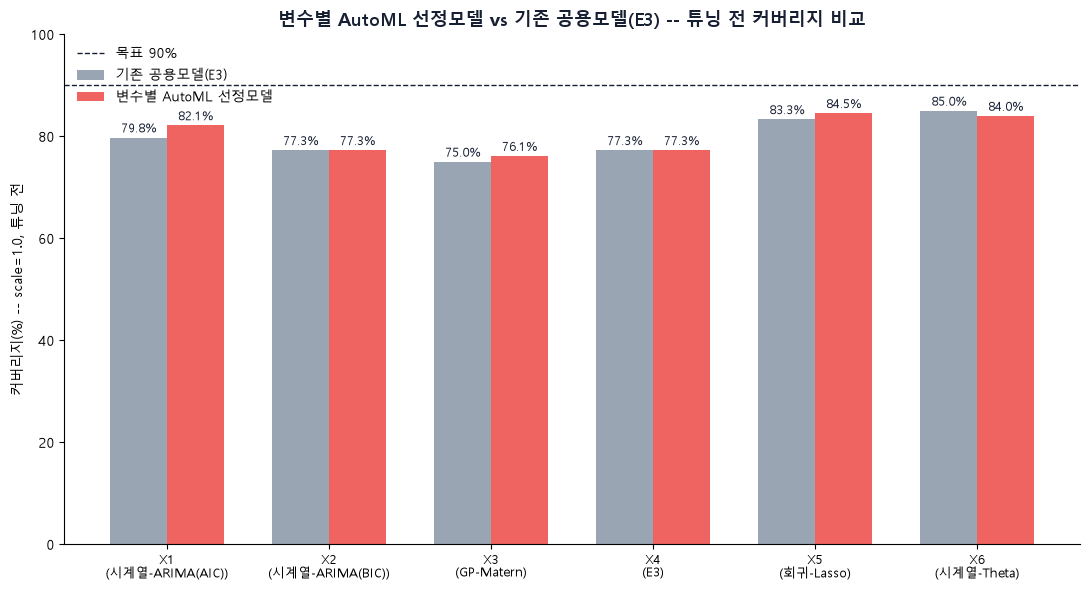

,E3(기존),AutoML 선정모델
X1,79.8,82.1
X2,77.3,77.3
X3,75.0,76.1
X4,77.3,77.3
X5,83.3,84.5
X6,85.0,84.0


In [7]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

def coverage_ensemble(models, var, scale=1.0, alpha=0.10, n_each=200):
    rngs = {m: rng_for(m) for m in models}
    sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == var)] for m in models}
    origins = sorted(sub[models[0]]["origin"].unique())
    rows = []
    for i in range(INITIAL_CALIB, len(origins)):
        for h in range(1, H + 1):
            pooled, actual_orig = [], None
            for m in models:
                g = sub[m]
                calib = g[g["origin"].isin(origins[:i])]
                test = g[g["origin"] == origins[i]]
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                actual_orig = row["actual_orig"]
                samples = row["fc_t"] + rngs[m].choice(calib_resid_h, size=n_each, replace=True)
                pooled.append(samples)
            pooled = np.concatenate(pooled)
            center = np.median(pooled)
            scaled = center + (pooled - center) * scale
            lo, hi = np.quantile(scaled, [alpha / 2, 1 - alpha / 2])
            rows.append(lo <= actual_orig <= hi)
    return np.mean(rows) * 100

e3_cov, chosen_cov, chosen_labels = [], [], []
for v in COLS:
    e3_cov.append(coverage_ensemble(E3, v))
    chosen_label = final_df.loc[LABELS[v], "최종 모델"]
    chosen_labels.append(chosen_label)
    if chosen_label == "E3":
        chosen_cov.append(e3_cov[-1])
    else:
        key = [k for k, lbl in FAMILY_LABELS.items() if lbl == chosen_label][0]
        chosen_cov.append(coverage_single(key, v))

x = np.arange(len(COLS))
width = 0.35
fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - width / 2, e3_cov, width, label="기존 공용모델(E3)", color="#9AA5B4")
b2 = ax.bar(x + width / 2, chosen_cov, width, label="변수별 AutoML 선정모델", color="#EF6461")
for bar, v in zip(b1, e3_cov):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", fontsize=9, color="#172033")
for bar, v in zip(b2, chosen_cov):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", fontsize=9, color="#172033")
ax.axhline(90, color="#172033", linestyle="--", linewidth=1, label="목표 90%")
ax.set_xticks(x)
ax.set_xticklabels([f"{LABELS[v]}\n({chosen_labels[i]})" for i, v in enumerate(COLS)], fontsize=9)
ax.set_ylabel("커버리지(%) -- scale=1.0, 튜닝 전")
ax.set_ylim(0, 100)
ax.set_title("변수별 AutoML 선정모델 vs 기존 공용모델(E3) -- 튜닝 전 커버리지 비교", fontsize=13, fontweight="bold", color="#172033")
ax.legend(frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

cov_compare = pd.DataFrame({"E3(기존)": np.round(e3_cov, 1), "AutoML 선정모델": np.round(chosen_cov, 1)}, index=[LABELS[v] for v in COLS])
display(cov_compare)


## 6. 공정 비교 — 둘 다 90%로 튜닝한 뒤 구간 폭(width) 비교

튜닝 전 커버리지만 비교하면 불공평하다(어차피 scale로 90%까지 맞출 거라서). **E3와 AutoML 선정모델을
각각 scale 튜닝해서 90%에 맞춘 다음, 그때의 평균 구간 폭을 비교**해야 "실제로 더 좁고 쓸모있는 구간을
주는가"를 알 수 있다.


In [8]:
def precompute_samples(kind, key_or_models, var, alpha=0.10):
    # 샘플을 한 번만 뽑아두고, scale 스윕은 그 샘플에 산술연산만 적용해서 빠르게 한다.
    pairs = []  # (samples_raw, center, actual_orig) per (origin,h)
    if kind == "single":
        rng = rng_for(key_or_models)
        e = err_df[(err_df["model"] == key_or_models) & (err_df["var"] == var)]
        origins = sorted(e["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = e[e["origin"].isin(origins[:i])]
            test = e[e["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
                pairs.append((samples, np.median(samples), row["actual_orig"]))
    else:
        models = key_or_models
        rngs = {m: rng_for(m) for m in models}
        sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == var)] for m in models}
        origins = sorted(sub[models[0]]["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            for h in range(1, H + 1):
                pooled, actual_orig = [], None
                for m in models:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == h]["err_t"].values
                    row = test[test["h"] == h].iloc[0]
                    actual_orig = row["actual_orig"]
                    samples = row["fc_t"] + rngs[m].choice(calib_resid_h, size=200, replace=True)
                    pooled.append(samples)
                pooled = np.concatenate(pooled)
                pairs.append((pooled, np.median(pooled), actual_orig))
    return pairs


def eval_pairs_at_scale(pairs, scale, alpha=0.10):
    covered, widths = [], []
    for samples, center, actual_orig in pairs:
        scaled = center + (samples - center) * scale
        lo, hi = np.quantile(scaled, [alpha / 2, 1 - alpha / 2])
        covered.append(lo <= actual_orig <= hi)
        widths.append(hi - lo)
    return np.mean(covered) * 100, np.mean(widths)


def tune_to_90(kind, key_or_models, var, target=90.0, scale_grid=np.arange(0.8, 3.01, 0.05)):
    pairs = precompute_samples(kind, key_or_models, var)
    best_scale, best_diff, best_cov, best_width = None, 1e9, None, None
    for s in scale_grid:
        cov, width = eval_pairs_at_scale(pairs, s)
        if abs(cov - target) < best_diff:
            best_diff, best_scale, best_cov, best_width = abs(cov - target), s, cov, width
    return best_scale, best_cov, best_width


width_rows = []
for v in COLS:
    e3_scale, e3_cov90, e3_width = tune_to_90("ensemble", E3, v)
    chosen_label = final_df.loc[LABELS[v], "최종 모델"]
    if chosen_label == "E3":
        ch_scale, ch_cov90, ch_width = e3_scale, e3_cov90, e3_width
    else:
        key = [k for k, lbl in FAMILY_LABELS.items() if lbl == chosen_label][0]
        ch_scale, ch_cov90, ch_width = tune_to_90("single", key, v)
    width_rows.append({"변수": LABELS[v], "모델": chosen_label,
                        "E3 scale": round(e3_scale, 2), "E3 커버리지": round(e3_cov90, 1), "E3 폭": round(e3_width, 2),
                        "선정모델 scale": round(ch_scale, 2), "선정모델 커버리지": round(ch_cov90, 1), "선정모델 폭": round(ch_width, 2)})

width_df = pd.DataFrame(width_rows).set_index("변수")
display(width_df)


,모델,E3 scale,E3 커버리지,E3 폭,선정모델 scale,선정모델 커버리지,선정모델 폭
변수,,,,,,,
X1,시계열-ARIMA(AIC),1.35,90.5,795.32,1.40,90.5,803.72
X2,시계열-ARIMA(BIC),1.75,90.9,0.03,1.55,89.8,0.03
X3,GP-Matern,1.50,90.9,886.98,1.70,89.8,980.62
X4,E3,1.50,89.8,0.14,1.50,89.8,0.14
X5,회귀-Lasso,1.50,90.5,0.31,1.05,90.5,0.21
X6,시계열-Theta,1.20,90.0,0.04,1.15,89.0,0.03


## 7. 실측 + 예측 팬차트 겹쳐 비교 (E3 vs AutoML 선정모델)

막대그래프 대신, 실측값 위에 두 방식의 미래 4분기 예측(중앙값+90% 구간)을 **같은 그래프에 겹쳐서** 그린다.
회색이 기존 공용모델(E3), 빨강이 AutoML 선정모델이다.


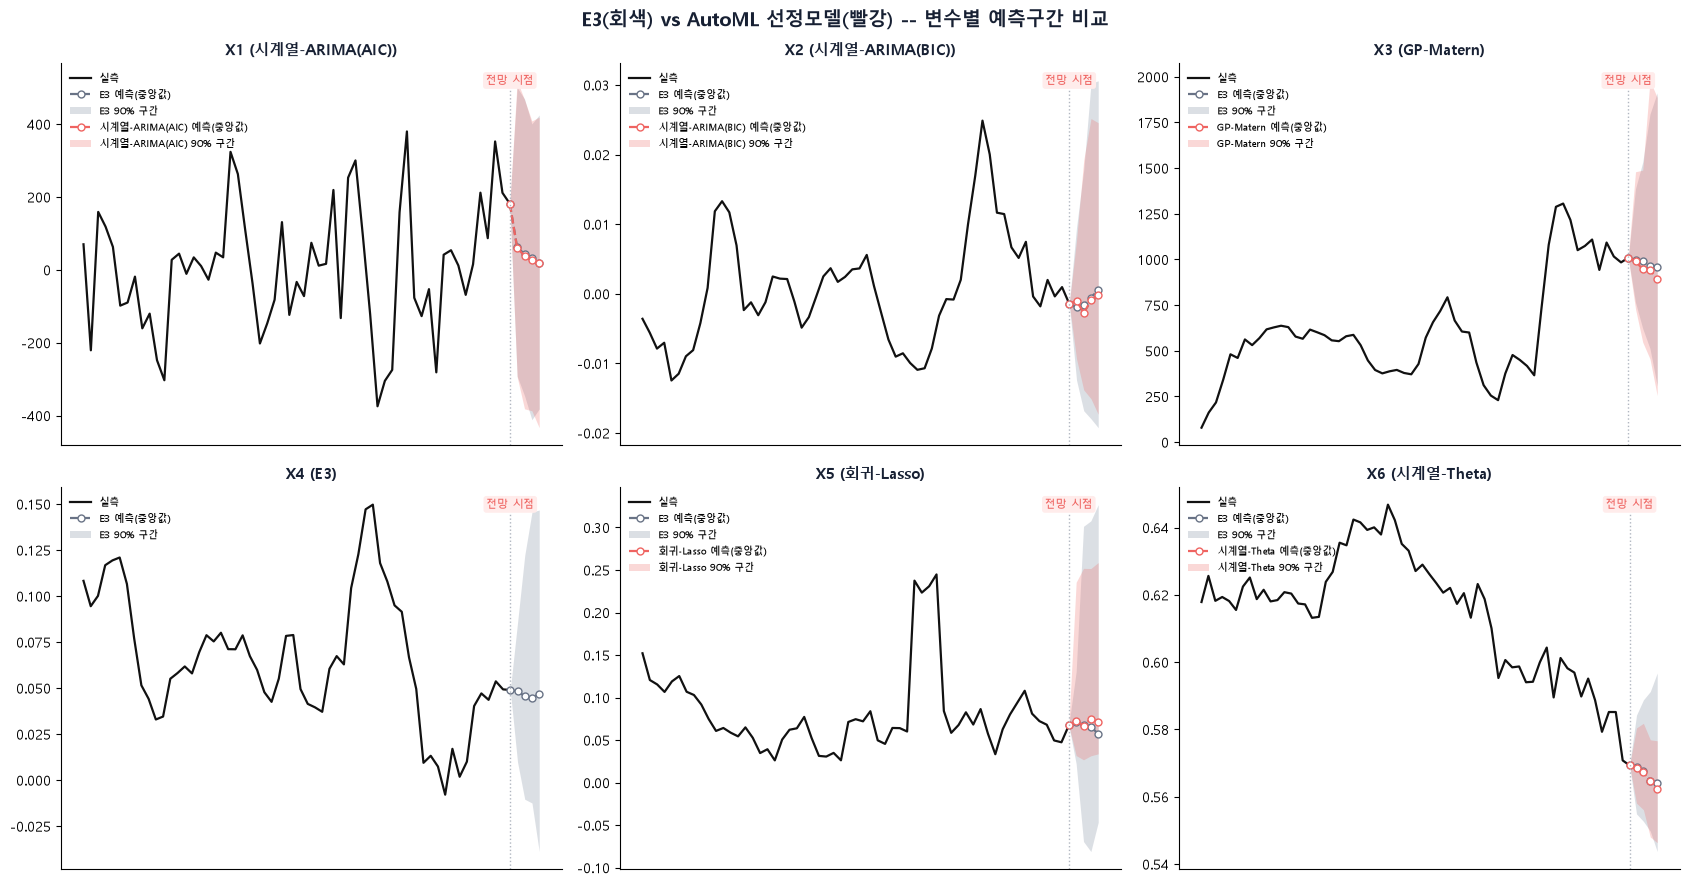

In [9]:
import pmdarima as pm
from sklearn.linear_model import LassoCV
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def fc_arima_aic(values, h=H):
    m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="aic")
    return np.asarray(m.predict(n_periods=h))

def fc_arima_bic(values, h=H):
    m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="bic")
    return np.asarray(m.predict(n_periods=h))

def fc_theta(values, h=H):
    n = len(values)
    slope = np.polyfit(np.arange(n), values, 1)[0]
    ses_fc = ExponentialSmoothing(values, trend=None, initialization_method="estimated").fit().forecast(h)
    return ses_fc + (slope / 2) * np.arange(1, h + 1)

def _fc_gp_kernel(values, h, kernel):
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    mean, _ = gp.predict(np.arange(n, n + h).reshape(-1, 1) / n, return_std=True)
    return mean

def fc_gp_matern(values, h=H):
    return _fc_gp_kernel(values, h, ConstantKernel(1.0) * Matern(1.0, nu=1.5) + WhiteKernel(1.0))

def fc_gp_rbf(values, h=H):
    return _fc_gp_kernel(values, h, ConstantKernel(1.0) * RBF(1.0) + WhiteKernel(1.0))

def fc_reg_lasso(values, h=H):
    return _recursive_forecast(lambda X, y: LassoCV(alphas=np.logspace(-3, 3, 13), max_iter=5000).fit(X, y), values, h)

FC_MAP = {"arima_aic": fc_arima_aic, "arima_bic": fc_arima_bic, "gp_matern": fc_gp_matern,
          "gp_rbf": fc_gp_rbf, "theta": fc_theta, "reg_lasso": fc_reg_lasso}


def build_fan(kind, key_or_models, var, scale):
    vals = raw[["quarter", var]].dropna()[var].values.astype(float)
    lo_h, hi_h, center_h = [], [], []
    if kind == "single":
        fc = FC_MAP[key_or_models](vals, H)
        rng = rng_for(key_or_models)
    else:
        models = key_or_models
        fc_each = {m: FC_MAP[m](vals, H) for m in models}
        rngs = {m: rng_for(m) for m in models}
    for h in range(1, H + 1):
        if kind == "single":
            calib_resid_h = err_df[(err_df["model"] == key_or_models) & (err_df["var"] == var) & (err_df["h"] == h)]["err_t"].values
            pooled = fc[h - 1] + rng.choice(calib_resid_h, size=500, replace=True)
        else:
            pooled = []
            for m in key_or_models:
                calib_resid_h = err_df[(err_df["model"] == m) & (err_df["var"] == var) & (err_df["h"] == h)]["err_t"].values
                pooled.append(fc_each[m][h - 1] + rngs[m].choice(calib_resid_h, size=200, replace=True))
            pooled = np.concatenate(pooled)
        center = np.median(pooled)
        scaled = center + (pooled - center) * scale
        lo, hi = np.quantile(scaled, [0.05, 0.95])
        lo_h.append(lo); hi_h.append(hi); center_h.append(center)
    return vals, np.array(center_h), np.array(lo_h), np.array(hi_h)


def plot_compare_fan(var, ax):
    e3_scale = width_df.loc[LABELS[var], "E3 scale"]
    vals, c_e3, lo_e3, hi_e3 = build_fan("ensemble", E3, var, e3_scale)
    n_hist = len(vals)
    x_hist = np.arange(n_hist)
    x_fc = np.arange(n_hist - 1, n_hist + H)

    ax.plot(x_hist, vals, color="#111111", linewidth=1.6, label="실측")
    ax.plot(x_fc, [vals[-1]] + list(c_e3), color="#697386", linewidth=1.6, linestyle="--", marker="o",
            markerfacecolor="white", markeredgecolor="#697386", markersize=5, label="E3 예측(중앙값)")
    ax.fill_between(x_fc, [vals[-1]] + list(lo_e3), [vals[-1]] + list(hi_e3), color="#9AA5B4", alpha=0.35, linewidth=0, label="E3 90% 구간")

    chosen_label = final_df.loc[LABELS[var], "최종 모델"]
    if chosen_label != "E3":
        key = [k for k, lbl in FAMILY_LABELS.items() if lbl == chosen_label][0]
        ch_scale = width_df.loc[LABELS[var], "선정모델 scale"]
        _, c_ch, lo_ch, hi_ch = build_fan("single", key, var, ch_scale)
        ax.plot(x_fc, [vals[-1]] + list(c_ch), color="#EF6461", linewidth=1.6, linestyle="--", marker="o",
                markerfacecolor="white", markeredgecolor="#EF6461", markersize=5, label=f"{chosen_label} 예측(중앙값)")
        ax.fill_between(x_fc, [vals[-1]] + list(lo_ch), [vals[-1]] + list(hi_ch), color="#EF6461", alpha=0.25, linewidth=0, label=f"{chosen_label} 90% 구간")

    ax.axvline(n_hist - 1, color="#B0B6C0", linestyle=":", linewidth=1, ymax=0.93)
    ax.annotate("전망 시점", xy=(n_hist - 1, 0.97), xycoords=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=8, color="#EF6461",
                bbox=dict(boxstyle="round,pad=0.25", fc="#FFECEB", ec="none"))
    ax.set_title(f"{LABELS[var]} ({chosen_label})", fontsize=10.5, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xticks([])
    ax.legend(loc="upper left", frameon=False, fontsize=7.5)


fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, v in zip(axes.flat, COLS):
    plot_compare_fan(v, ax)
fig.suptitle("E3(회색) vs AutoML 선정모델(빨강) -- 변수별 예측구간 비교", fontsize=14, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


## 8. 스케일 보정판 — 상대 배율(선정모델 폭 ÷ E3 폭)

변수마다 원래 값 스케일이 완전히 달라서(X1는 수백, X2는 0.0X대) 절대 폭으로 그리면 작은 변수가
안 보인다. E3=1.0 기준 상대 배율로 다시 그린다 -- 1.0보다 작으면 AutoML 선정모델이 더 좁고(좋음),
크면 더 넓다(나쁨).


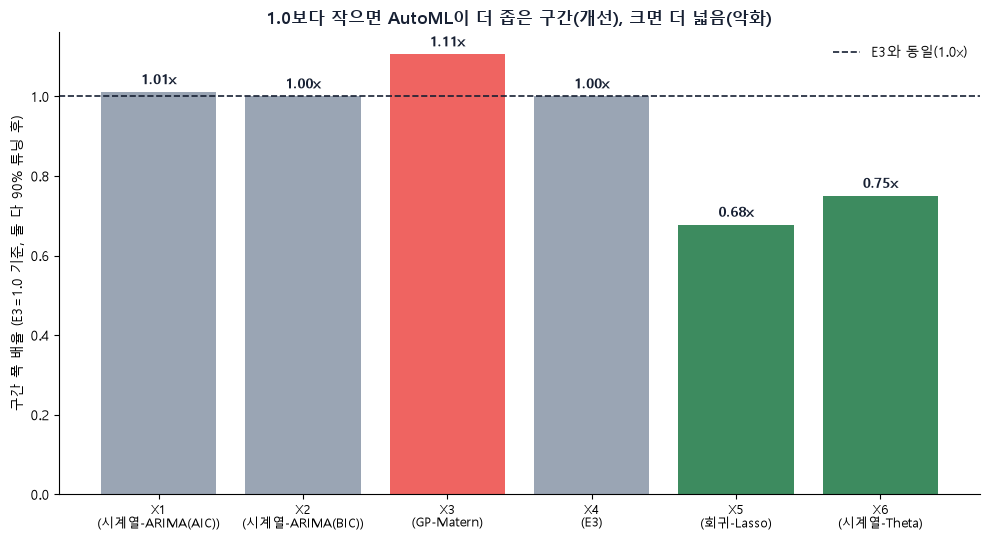

In [10]:
ratio = (width_df["선정모델 폭"] / width_df["E3 폭"]).values
colors_r = ["#9AA5B4" if abs(r - 1.0) < 0.02 else ("#3D8B5F" if r < 1.0 else "#EF6461") for r in ratio]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(range(len(COLS)), ratio, color=colors_r)
for i, r in enumerate(ratio):
    ax.text(i, r + 0.02, f"{r:.2f}x", ha="center", fontsize=10, fontweight="bold", color="#172033")
ax.axhline(1.0, color="#172033", linestyle="--", linewidth=1.2, label="E3와 동일(1.0x)")
ax.set_xticks(range(len(COLS)))
ax.set_xticklabels([f"{LABELS[v]}\n({width_df.loc[LABELS[v], '모델']})" for v in COLS], fontsize=9)
ax.set_ylabel("구간 폭 배율 (E3=1.0 기준, 둘 다 90% 튜닝 후)")
ax.set_title("1.0보다 작으면 AutoML이 더 좁은 구간(개선), 크면 더 넓음(악화)", fontsize=12.5, fontweight="bold", color="#172033")
ax.legend(frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()
